# Application in Python

### Connecting to MySQL server and databases

In [1]:
import os
import mysql.connector
from mysql.connector import Error

try:
    connection = mysql.connector.connect(
        host='localhost',
        database='restaurant_db',
        user='root',
        password=os.environ.get("DB_PASSWORD")
        #auth_plugin = 'mysql_native_password'
    )
    if connection.is_connected():
        db_Info = connection.get_server_info()
        print("Connected to MySQL Server version ", db_Info)
        cursor = connection.cursor()
        cursor.execute("select database();")
        record = cursor.fetchone()
        print("Your connected to database: ", record)
        #
        sql_select_Query = "select * from RESERVATION LIMIT 1"
        cursor = connection.cursor()
        cursor.execute(sql_select_Query)
        records = cursor.fetchall()
        print("\none data row in RESERVATION:")
        for row in records:
            print('reservationID =',row,"\n")

except Error as e:
    print("Error while connecting to MySQL", e)
finally:
    if (connection.is_connected()):
        cursor.close()
        connection.close()
        print("MySQL connection is closed")
        
#you should see the following output
#'''Connected to MySQL Server version 8.0.17
#Your connected to database: ('classicmodels',)
#True
#MySQL connection is closed'''


Connected to MySQL Server version  9.5.0
Your connected to database:  ('restaurant_db',)

one data row in RESERVATION:
reservationID = (1, '', 5, datetime.datetime(2026, 3, 21, 17, 0), '1', 7) 

MySQL connection is closed


In [2]:
import os
import mysql.connector
from mysql.connector import Error
import pandas as pd
import matplotlib.pyplot as plt

try:
    connection = mysql.connector.connect(
        host='localhost',
        database='restaurant_db',
        user='root',
        password=os.environ.get("DB_PASSWORD")
    )
    if connection.is_connected():
        print("Connected!")
except Error as e:
    print("Error:", e)

Connected!


In [3]:
import os
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import pandas as pd
#import mysql.connector
import matplotlib.pyplot as plt

engine = create_engine(URL.create(
    "mysql+mysqlconnector",
    username="root",
    password=os.environ.get("DB_PASSWORD"),
    host="localhost",
    database="restaurant_db",
))
print("Engine Connected!")

Engine Connected!


### Query1: Total Tips Earned by Each Server

      name  total_tips
0      Bob        45.0
1      Eve        38.0
2    Alice        36.0
3  Charlie        27.0
4    David        27.0


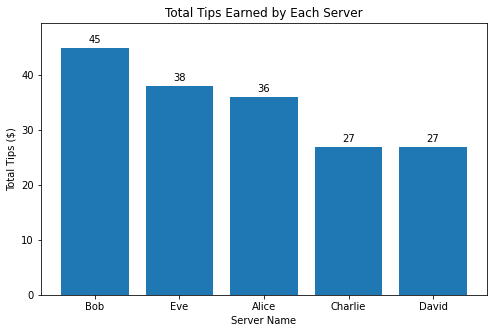

In [4]:
from sqlalchemy import text

# Wrap query in the text() function
query1 = text("""
select a.name, sum(b.tips_earned) total_tips from server a
  join PERFORMANCE_METRICS b on a.serverid = b.serverid
 group by a.name
 order by sum(b.tips_earned) desc;
""")

# Use the engine.connect() with the wrapped query
with engine.connect() as conn:
    df_tips = pd.read_sql(query1, conn)
print(df_tips)

# Plot
plt.figure(figsize=(8, 5))
bars = plt.bar(df_tips['name'], df_tips['total_tips'])
plt.bar_label(bars, padding=3)
plt.title('Total Tips Earned by Each Server')
plt.xlabel('Server Name')
plt.ylabel('Total Tips ($)')
plt.ylim(0, max(df_tips['total_tips']) * 1.1)
plt.show()

#### Analytics of Query1: Total Tips Earned by Each Server

Bob earned the highest amount of tips at 45. Although Charlie and David earned the least tips, they still received 27 each. Thus, there is a difference of 18 between the highest earner and the lowest earner.

### Query2: Popularity of The Reservation in Each Dining Time 

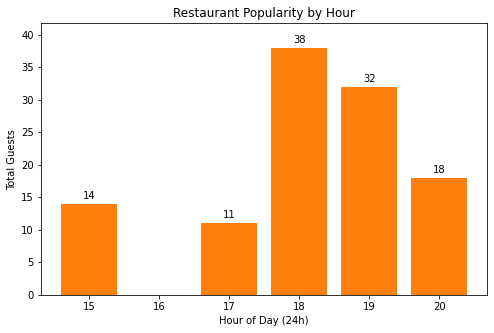

In [5]:
query2 = text("""
select HOUR(date_time) AS res_hour, sum(party_size) popularity
  from RESERVATION 
 where status=1
 group by HOUR(date_time)
 order by HOUR(date_time);
""")

with engine.connect() as conn2:
    df_pop = pd.read_sql(query2, conn2)

# Plot
plt.figure(figsize=(8, 5))
plt.bar(df_pop['res_hour'], df_pop['popularity'])
bars = plt.bar(df_pop['res_hour'], df_pop['popularity'])
plt.bar_label(bars, padding=3)
plt.title('Restaurant Popularity by Hour')
plt.xlabel('Hour of Day (24h)')
plt.ylabel('Total Guests')
plt.ylim(0, max(df_pop['popularity']) * 1.1)
plt.show()

#### Analytics of Query2: Popularity of The Reservation in Each
Reservation popularity peaks between 18:00 and 19:00, and there are no recorded reservations at 16:00. However, the period around 16:00 remains a potential opportunity for growth or happy hour promotions due to the lack of bookings.

### Query3: Number of Tables taken by Servers

      name  Number_of_Tables
0    Alice                10
1      Bob                 8
2  Charlie                 6
3    David                 6
4      Eve                 4
5      Sam                 3


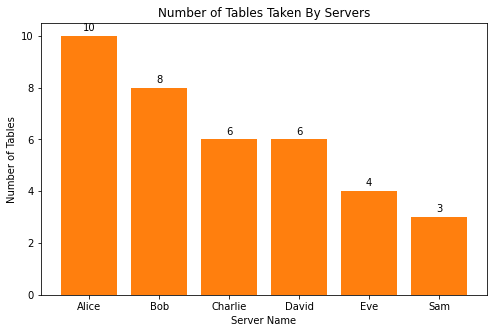

In [6]:
query3 = text("""
select s.name, COUNT(sa.assignmentID) as Number_of_Tables
    from SERVER s
    join SEATING_ASSIGNMENT sa on s.serverID = sa.serverID
    group by s.name, s.serverID
    order by Number_of_Tables DESC;
""")

with engine.connect() as conn3:
    df_assignments = pd.read_sql(query3, conn3)
    print(df_assignments)

# Plot
plt.figure(figsize=(8, 5))
plt.bar(df_assignments['name'], df_assignments['Number_of_Tables'])
bars = plt.bar(df_assignments['name'], df_assignments['Number_of_Tables'])
plt.bar_label(bars, padding=3)
plt.title('Number of Tables Taken By Servers')
plt.xlabel('Server Name')
plt.ylabel('Number of Tables')
plt.show()

#### Analytics of Query3: Number of Tables taken by Servers 
Overall, Alice has taken the most tables (10). Charlie and David have taken the same number of tables (6). Sam has taken the least tables (3).

### Query4: Guest Notes

In [7]:
query4 = text("""
select g.guestName, g.guestID, gn.note_content, gn.note_date, r.reservationID
    from guest g 
    join has_notes hn on g.guestID = hn.guestID
    join guest_note gn on hn.noteID = gn.noteID
    left join reservation r on g.guestID = r.guestID;
""")

with engine.connect() as conn4:
    df_notes = pd.read_sql(query4, conn4)
    print(df_notes)

  guestName  guestID          note_content   note_date  reservationID
0       max       14      Regular customer  2026-03-20           36.0
1      will       20   Allergic to peanuts  2026-03-20            NaN
2       jen       19   Allergic to peanuts  2026-03-20            NaN
3     ellen       16      Regular customer  2026-03-20            NaN
4       zoe        5  Birthday celebration  2026-03-20            3.0


#### Analytics of Query4: Guest Notes
Max and Zoe are 2 guests who have notes and have a reservation on 3/20/26. Max is a “regular customer,” and Zoe has a “birthday celebration” tonight. There are 3 remaining guests who have notes taken on them, with no reservation. Will and Jen are both “Allergic to peanuts,” and Ellen is a “regular customer”.